#  A ConvNet for the 2020s
### 1. Introduction & Background (Why ConvNeXt?)

* **The Shift:** In the 2010s, ConvNets (like ResNet) dominated computer vision due to efficient sliding windows. In 2020, Vision Transformers (ViTs) introduced global attention, bringing high accuracy but high computational costs for high-resolution images.
* **The Hybrid Approach:** Swin Transformers combined local windows with transformers, proving convolutions are still vital.
* **The Core Idea:** The authors asked: *What if we modernize a pure ResNet to match a Transformer's design without using attention modules?*
* **The Result:** **ConvNeXt**, a pure ConvNet that matches or beats Transformers in accuracy and efficiency.

<p align="left">
  <img src="https://drive.google.com/uc?export=view&id=13tsrd4S1lGRktEf2IsuC5XjB9f2KJJMT" width="400">
</p>


### 2 The Modernization Roadmap (Training & Macro Design)
#### Training Techniques
Originally, the performance of ResNet-50 is 76.1% on ImageNet.
To improve it, they used the following:
1. Upgraded training from 90 to **300 epochs**: Increasing the training duration to 300 epochs allows the model more time to converge and learn better feature representations.
<br> <br>
2. Adopted **AdamW optimizer**: Replacing the traditional SGD optimizer (Stochastic Gradient Descent) with AdamW improves optimization stability and generalization, which is a standard recipe in modern vision architectures (similar to Vision Transformers).
<br> <br>
3. Used advanced **Data Augmentation** (Mixup, Cutmix, RandAugment, Random Erasing)
Originally, the performance of ResNet-50 is 76.1% on ImageNet. To improve it, they used the following:

<p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1F0LQ1ORVwwJCOqcYVkyiIa7MiTRK1a06" width="400">
  <img src="https://drive.google.com/uc?export=view&id=1Sy1RV45FE2UuCq5tqWr3vDbVjv5vOfjH" width="400">
</p>


*  &nbsp; &nbsp; &nbsp; **Mixup:** Blending two images from different classes with specific ratios, and modifying the label to be proportionally weighted according to the blended image.
*   &nbsp; &nbsp; &nbsp; **CutMix:** Cutting a portion of an image and pasting another image in its place, then calculating the pixel ratio to determine the new label weight.


*  &nbsp; &nbsp; &nbsp; **RandAugment:** Applying random augmentations such as shearing, rotation, and color jittering.

*  &nbsp; &nbsp; &nbsp; **Random Erasing:** Randomly cropping or erasing a region of an image and filling it with random noise (such as a normal distribution).
<br>


4. Used **Regularization Techniques** (Stochastic Depth, Label Smoothing).

*  &nbsp; &nbsp; &nbsp; **Stochastic Depth:** Randomly dropping residual blocks during training only, while keeping all of them during inference.
<br> <br>
*  &nbsp; &nbsp; &nbsp; **Label Smoothing:** Modifying one-hot labels to prevent the model from becoming overconfident and overfitting.


<br>

**Impact:** Boosted ResNet-50 accuracy from 76.1% to **78.8%** just by improving the training recipe.



<p align="left">
  <img src="https://drive.google.com/uc?export=view&id=156qSTDeejp4I_rTwro8GqFUjPHcIFlJe" width="400">
</p>


###  3 Macro Design

**A) Changing Stage Compute Ratio:**
<p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1XAGS7X1aOF1Qx2YKTFZDPocMWQrOX-ic" width="700">
</p>


  * ResNet's block distribution across its 4 stages was empirically set to `(3, 4, 6, 3)`.

  * Following Swin-T, this was adjusted to `(3, 3, 9, 3)` (allocating more computation to stage 3), raising accuracy to 79.4%.
  <p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1gX5m9ulp2uFvww3jgdRowCB8BP3ld9Jh" width="400">
</p>



In [ ]:
# Base Variables & Parameters
in_chans = 3
dims = [96, 192, 384, 768]
depths = [3, 3, 9, 3]


**B) Changing Stem to "Patchify":**

  * Traditional ResNets begin with a heavy $7\times7$ convolution (stride 2) and max pooling.

  * ViTs/Swin use a non-overlapping "patchify" stem. Replacing ResNet's stem with a simple $4\times4$ stride-4 convolution yielded 79.5% accuracy.
<p align="left">
<img src="https://drive.google.com/uc?export=view&id=1mPKo-Utvxdc0FFhRdVd51VIsxb4nYGN9" width="300">
  <img src="https://drive.google.com/uc?export=view&id=18yF5Wilg5mxaKCkQer3dINEUkynYPDk3" width="400">
</p>


In [ ]:
# 3. Concise Input Stem (Patchify)
stem = nn.Sequential(
    nn.Conv2d(in_chans, dims[0], kernel_size=4, stride=4),
    LayerNorm(dims[0], eps=1e-6, data_format="channels_first")
)

### Architecture Modernization (ResNeXt & Inverted Bottleneck)

#### ResNeXt-ify & Depthwise Conv
<p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1JrVu3zpMtawhL4AXuO-SKxoC3kk3jrgE" width="600">
</p>

* Adopted **Depthwise Convolution** to separate spatial and channel mixing (mimicking self-attention).
* Expanded network width (channels from 64 to **96**), pushing accuracy to **80.5%**.
   <p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1T2OQmjsfz5bATssM295qyJdc0ymViecW" width="400">
</p>


###  Inverted Bottleneck

**Transformer** blocks use an inverted bottleneck design where the hidden dimension is 4 times wider than the input dimension (popularized by MobileNetV2).
   <p align="left">
  <img src="https://drive.google.com/uc?export=view&id=1KdlJMLvin9O7RKsj3p5QRHQtwA_hRV8H" width="500">
</p>
(a) is a ResNeXt block; in (b) they created an inverted bottleneck block

 Surprisingly, despite the depthwise layer changes, this reduces total network FLOPs to 4.6G while slightly boosting performance to 80.6%.

### Large Kernel Sizes

ResNets use 3×3 kernels, which means each layer looks at a small 3×3 patch.

Transformers use self-attention, which gives a much wider view. Even Swin uses 7×7 windows.

So the authors give ConvNeXt a bigger view: a **7×7 depthwise convolution**.

**BUT** Applying a large kernel directly on wide channels (e.g., 384) causes a massive surge in computational cost (FLOPs).

To fix this, they use an inverted bottleneck and move the depthwise convolution to the top of the block, operating on 96 channels instead of 384.

**Moving** the conv layer up successfully reduced the computational cost ($FLOPs$), though it initially caused a temporary dip in accuracy. However, pairing it with a $7 \times 7$ large kernel fully recovered and boosted the accuracy while keeping computational complexity low and efficient.





In [ ]:
self.dwconv = nn.Conv2d(dim, dim, kernel_size=7, padding=3, groups=dim)



- 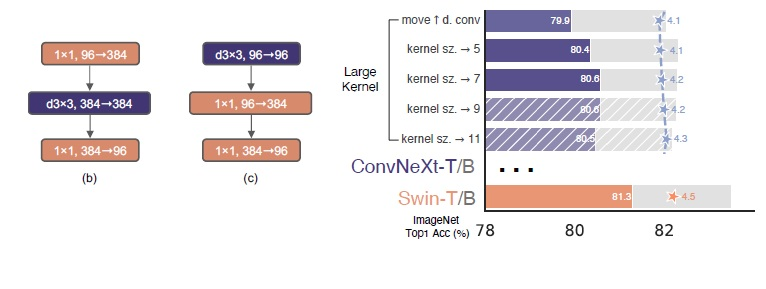
- **Result:**

- 3×3 → 7×7: accuracy rises from 79.9% to **80.6%** at about the same FLOPs.
- Gains stop at 7×7, so larger kernels don't help.

### 4- Micro Design: Replacing ReLU with GELU

**ReLU** is the standard activation in ConvNets because it is simple and efficient. But the most advanced Transformers (BERT, GPT-2, ViT) use **GELU**, a smoother variant of ReLU.

- **Result :** accuracy stays the same at **80.6%**. GELU doesn't improve accuracy here, but it brings the design closer to Transformers at no cost.

In [ ]:
self.act = nn.GELU()

###  Micro Design: Fewer Activation Functions

**In a ResNet block**, an activation follows *every* conv layer. A Transformer block has only **one** activation.

They remove all GELU from the block except the one between the two 1×1 layers.

**Result :** accuracy improves from 80.6% to **81.3%** (+0.7%), practically matching Swin-T. This is the biggest single gain in the micro design steps.

In [ ]:
x = self.pwconv1(x)
x = self.act(x)
x = self.pwconv2(x)

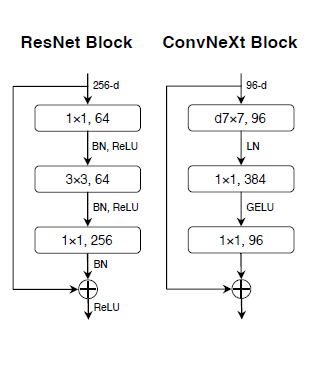

- 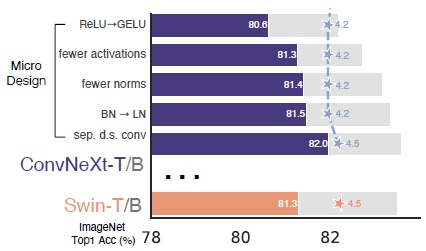

### Micro Design: Fewer Norms, and BatchNorm → LayerNorm

**Transformer** blocks also have fewer normalization layers than **ResNet** blocks.

They remove two of the three BatchNorm layers, keeping one. Accuracy rises to **81.4%**, already above Swin-T (81.3%).

**BatchNorm → LayerNorm:**

BatchNorm is the standard in ConvNets, but Transformers use the **LayerNorm**.

- **BatchNorm:** takes a group of numbers that belong to **one channel, collected across all the images in the batch**. The result depends on the other images.
- **LayerNorm:** takes a group of numbers that belong to **one single element**  The result depends only on that element.

**Result** BatchNorm → LayerNorm
The accuracy improves slightly to **81.5%**.



In [ ]:
self.norm = LayerNorm(dim, eps=1e-6)

In [ ]:
x = self.dwconv(x)
x = x.permute(0, 2, 3, 1)
x = self.norm(x)
x = self.pwconv1(x)

### Micro Design: Separate Downsampling Layers

In ResNet, the first block of each stage aso shrinks the image (stride 2). Swin Transformers instead use a **separate layer** to downsample between stages.

**ConvNeXt** use a dedicated 2×2 conv with stride 2 for downsampling.

**The problem:** training diverged at first. The fix was adding **LayerNorm wherever the resolution changes**: before each downsampling layer, after the stem, and after the final pooling.

**Result (paper):** accuracy reaches **82.0%**, exceeding Swin-T (81.3%). This is the final **ConvNeXt-T**.

In [ ]:
 downsample_layer = nn.Sequential(
        LayerNorm(dims[i], eps=1e-6, data_format="channels_first"),
        nn.Conv2d(dims[i], dims[i+1], kernel_size=2, stride=2),
 )

**Result :** accuracy reaches **82.0%**, exceeding Swin (81.3%). This is the final **ConvNeXt**.
- 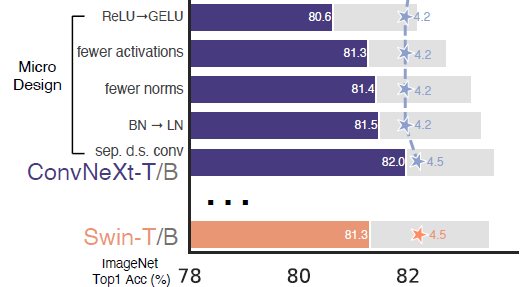

### 5- Results A: ImageNet Classification (Table 1)

ConvNeXt matches or beats Swin-Transformer at similar complexity, and runs slightly faster.

| Model | Accuracy | Throughput (img/s) |
|---|---|---|
| Swin-T | 81.3% | 757.9 |
| **ConvNeXt-T** | **82.1%** | **774.7** |
| Swin-B (384²) | 84.5% | 85.1 |
| **ConvNeXt-B (384²)** | **85.1%** | **95.7** (+12.5%) |

*(Throughput measured on a V100 GPU.)*

### Results B: Speed and Scalability

**Faster on modern hardware:** on an A100 GPU, ConvNeXt reaches up to **~49% higher throughput** than Swin (Table 12).

**It scales:** with ImageNet-22K pre-training, ConvNeXt-XL reaches **87.8%** top-1. This shows that a pure ConvNet can scale as well as a Transformer.

### Results C: Detection and Segmentation

ConvNeXt backbones are on par or better than Swin on downstream tasks.

| Task | Swin-B | ConvNeXt-B |
|---|---|---|
| COCO detection  | 53.0 | **54.0** |
| ADE20K segmentation  | 51.7 | **53.1** |

*(Both pre-trained on ImageNet-22K. For smaller models such as the T variant, results are roughly equal, e.g. 46.0 vs. 46.2 AP.)*

### 6- Conclusion

- A **pure ConvNet**, with no attention, can compete with hierarchical Vision Transformers in accuracy, speed, and scalability.
- The gains came from **modernizing a ResNet step by step**: better training, large kernels, inverted bottleneck, and Transformer-style micro design.
- Most of these ideas are not new. Their power comes from combining them.

**Limitation:** Transformers may still be more flexible for multi-modal tasks and structured outputs.



### 7- Demo Results: ConvNeXt-T vs. Swin-T

We tested both models on **500 images** from Imagenette (10 classes taken from  Throughput is measured on a GPU with batch size 64.

| Model | Accuracy (%) | Throughput (images/s) |
|---|---|---|
| **ConvNeXt-T** | **90.20** | **236.5** |
| Swin-T | 87.40 | 205.1 |

**Observations:**
- ConvNeXt-T was more accurate (+2.8 points) on this small test.
- ConvNeXt-T also had about **15% higher throughput**.
- This matches the direction of the paper's results (Table 1: 82.1% vs. 81.3% accuracy, and 774.7 vs. 757.9 images/s).


### 8- Reference

**APA:**
Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., & Xie, S. (2022). A ConvNet for the 2020s. *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition (CVPR)*. arXiv:2201.03545. https://arxiv.org/abs/2201.03545

**IEEE:**
Z. Liu, H. Mao, C.-Y. Wu, C. Feichtenhofer, T. Darrell, and S. Xie, "A ConvNet for the 2020s," in *Proc. IEEE/CVF Conf. Computer Vision and Pattern Recognition (CVPR)*, 2022, arXiv:2201.03545.

**Code:** https://github.com/facebookresearch/ConvNeXt